<a href="https://www.kaggle.com/code/lofoga/bacteria-characterization-model-c?scriptVersionId=350519325" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [12]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("orvile/bccd-blood-cell-count-and-detection-dataset")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/datasets/orvile/bccd-blood-cell-count-and-detection-dataset


## Cell 1: Setup

Imports the libraries needed for the project:
- **os, glob, json** – find and read files
- **cv2** – image loading and processing
- **numpy, pandas** – data handling
- **matplotlib** – plotting results
- **skimage** – texture features (GLCM)
- **sklearn** – scaling, PCA, kNN, SVM, and evaluation metrics

Also sets the dataset path (`BASE`) and the three data splits (`train`, `val`, `test`).

In [18]:
import os, glob, json
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from skimage.feature import graycomatrix, graycoprops
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

BASE = "/kaggle/input/datasets/orvile/bccd-blood-cell-count-and-detection-dataset"
SPLITS = ["train", "val", "test"]

## Cell 2: Read Labels

Reads the JSON annotation files and pulls out the info needed for each blood cell:

1. Loops through `train`, `val`, and `test` folders
2. Opens each `.json` file (one per image)
3. For every labeled cell inside it, grabs:
   - **label** – cell type (e.g. RBC, WBC, Platelets)
   - **bbox** – box coordinates showing where the cell is in the image
4. Stores everything in a table (`df`), one row per cell

Last line prints how many cells exist per label, so you can check the data loaded correctly.

In [14]:
def parse_supervisely_annotations(base, splits):
    records = []
    for split in splits:
        ann_dir = os.path.join(base, split, "ann")
        img_dir = os.path.join(base, split, "img")
        for ann_file in glob.glob(os.path.join(ann_dir, "*.json")):
            with open(ann_file) as f:
                data = json.load(f)

            # image filename = json filename minus ".json"
            img_filename = os.path.basename(ann_file).replace(".json", "")

            for obj in data.get("objects", []):
                label = obj["classTitle"]
                points = obj["points"]["exterior"]  # [[x1,y1],[x2,y2]]
                (x1, y1), (x2, y2) = points
                xmin, xmax = sorted([x1, x2])
                ymin, ymax = sorted([y1, y2])
                records.append({
                    "filename": img_filename,
                    "split": split,
                    "label": label,
                    "bbox": (int(xmin), int(ymin), int(xmax), int(ymax))
                })
    return pd.DataFrame(records)

df = parse_supervisely_annotations(BASE, SPLITS)
print(df["label"].value_counts())
df.head()

label
RBC          4155
WBC           372
Platelets     361
Name: count, dtype: int64


,filename,split,label,bbox
0,BloodImage_00355.jpeg,train,RBC,"(27, 135, 146, 245)"
1,BloodImage_00355.jpeg,train,RBC,"(192, 228, 307, 368)"
2,BloodImage_00355.jpeg,train,RBC,"(67, 24, 186, 134)"
3,BloodImage_00355.jpeg,train,RBC,"(282, 168, 381, 281)"
4,BloodImage_00355.jpeg,train,RBC,"(271, 338, 372, 448)"


## Cell 3: Crop Each Cell

Uses the bounding boxes from `df` to cut out each individual cell from its full image.

1. For every row (one cell), loads the matching image
2. Skips it if the image can't be found
3. Cuts out just the cell using its box coordinates
4. Skips empty/invalid crops
5. Saves each small cropped cell image (`crops`) and its label (`labels`)

Last line prints the total number of cells successfully cropped, so you can confirm nothing important was lost.

In [15]:
def crop_cells(df, base):
    crops, labels = [], []
    for _, row in df.iterrows():
        img_path = os.path.join(base, row["split"], "img", row["filename"])
        img = cv2.imread(img_path)
        if img is None:
            continue
        xmin, ymin, xmax, ymax = row["bbox"]
        crop = img[ymin:ymax, xmin:xmax]
        if crop.size == 0:
            continue
        crops.append(crop)
        labels.append(row["label"])
    return crops, labels

crops, labels = crop_cells(df, BASE)
print("Total cropped cells:", len(crops))

Total cropped cells: 4886


## Cell 4: Feature Engineering

Turns each cropped cell image into a set of numbers (a feature vector) that kNN/SVM can learn from.

**Shape features** (from the cell's outline):
- **area** – size of the cell
- **perimeter** – length of its border
- **circularity** – how round the cell is (1 = perfect circle)

**Color features**:
- **mean** and **std** of color in each channel (Blue, Green, Red)

**Texture features** (via GLCM — checks how pixel brightness patterns repeat):
- **contrast** – how much brightness varies
- **homogeneity** – how smooth/uniform it looks
- **energy** – how orderly the pattern is
- **correlation** – how predictable neighboring pixels are

All these numbers are combined into one vector per cell (`X`), with `y` holding the matching labels.

Last line prints the shape of `X` — confirms how many cells and how many features per cell.

In [16]:
def extract_features(crop):
    """Returns one feature vector per cropped cell image."""
    img = cv2.resize(crop, (64, 64))
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
 
    # --- Shape features (via largest contour) ---
    _, thresh = cv2.threshold(gray, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    contours, _ = cv2.findContours(thresh, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if contours:
        c = max(contours, key=cv2.contourArea)
        area = cv2.contourArea(c)
        perimeter = cv2.arcLength(c, True)
        circularity = (4 * np.pi * area) / (perimeter ** 2 + 1e-6)
    else:
        area, perimeter, circularity = 0, 0, 0
 
    # --- Color features: mean + std per BGR channel ---
    color_mean = img.mean(axis=(0, 1))
    color_std = img.std(axis=(0, 1))
 
    # --- Texture features: GLCM (contrast, homogeneity, energy, correlation) ---
    glcm = graycomatrix(gray, distances=[1], angles=[0], symmetric=True, normed=True)
    contrast = graycoprops(glcm, "contrast")[0, 0]
    homogeneity = graycoprops(glcm, "homogeneity")[0, 0]
    energy = graycoprops(glcm, "energy")[0, 0]
    correlation = graycoprops(glcm, "correlation")[0, 0]
 
    return np.array([
        area, perimeter, circularity,
        *color_mean, *color_std,
        contrast, homogeneity, energy, correlation
    ])
 
feature_list = [extract_features(c) for c in crops]
X = np.array(feature_list)
y = np.array(labels)
print("Feature matrix shape:", X.shape)

Feature matrix shape: (4886, 13)


## Cell 5: Scale + Reduce Features (PCA), Split Data

1. **Scale** – puts all features on the same range, so no single feature (like "area") unfairly dominates others (like "circularity")
2. **PCA** – compresses the features into fewer numbers while keeping 95% of the useful information; removes overlap between related features and speeds up training
3. **Split** – divides the data into training (80%) and testing (20%) sets, keeping the class balance the same in both (`stratify=y`)

Print line shows how many features existed before and after PCA.

In [19]:
# %% [Cell 5] Scale features + apply PCA
# PCA compresses correlated features (e.g. area & perimeter) into fewer components,
# keeps the info that separates classes best, and speeds up training.
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
 
pca = PCA(n_components=0.95)  # keep 95% of variance
X_pca = pca.fit_transform(X_scaled)
print("Original dims:", X_scaled.shape[1], "-> PCA dims:", X_pca.shape[1])
 
X_train, X_test, y_train, y_test = train_test_split(
    X_pca, y, test_size=0.2, random_state=42, stratify=y
)
 

Original dims: 13 -> PCA dims: 7


## Cell 6: Train and Test kNN and SVM

**Training:**
- **kNN** (`n_neighbors=5`) – classifies a cell by looking at its 5 most similar cells in the training data and picking the most common label among them
- **SVM** (`kernel="rbf"`) – draws curved boundaries between the cell classes to separate them

Each model learns from `X_train`/`y_train`, then predicts labels for the unseen test set (`X_test`).

**Evaluation:**
- **Accuracy** – percentage of test cells classified correctly
- **Classification report** – precision, recall, and F1-score for each class (Platelets, RBC, WBC)
- **Confusion matrices** – side-by-side grids showing, for each true class, what the model predicted. The diagonal shows correct predictions; anything off the diagonal is a mistake

=== kNN Results ===
Accuracy: 0.9959100204498977
              precision    recall  f1-score   support

   Platelets       0.97      0.99      0.98        72
         RBC       1.00      1.00      1.00       831
         WBC       1.00      0.97      0.99        75

    accuracy                           1.00       978
   macro avg       0.99      0.99      0.99       978
weighted avg       1.00      1.00      1.00       978

=== SVM Results ===
Accuracy: 0.9979550102249489
              precision    recall  f1-score   support

   Platelets       0.99      1.00      0.99        72
         RBC       1.00      1.00      1.00       831
         WBC       1.00      0.99      0.99        75

    accuracy                           1.00       978
   macro avg       1.00      1.00      1.00       978
weighted avg       1.00      1.00      1.00       978



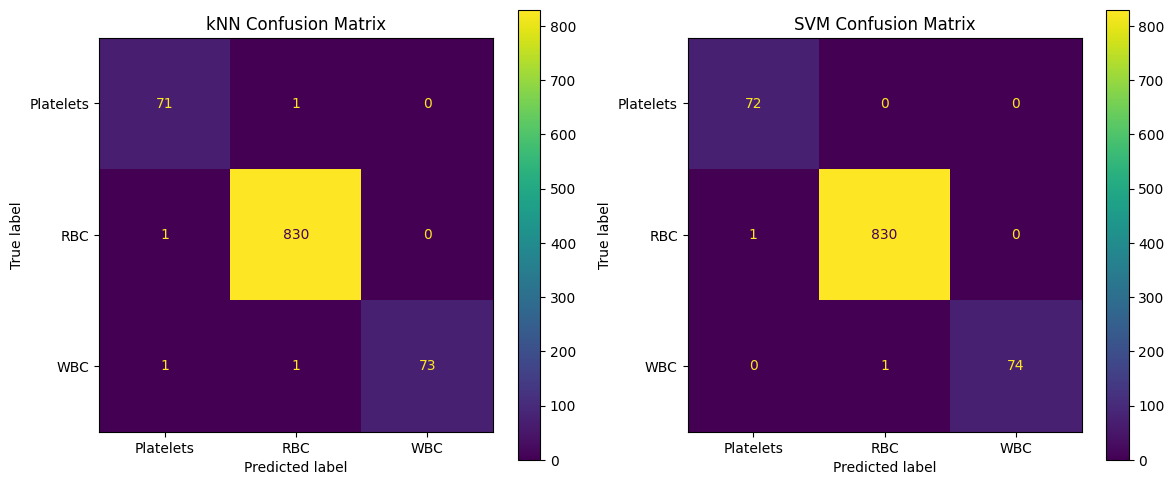

In [20]:
# %% [Cell 6] Train kNN and SVM, then evaluate
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train, y_train)
knn_pred = knn.predict(X_test)
 
svm = SVC(kernel="rbf", C=1.0, gamma="scale")
svm.fit(X_train, y_train)
svm_pred = svm.predict(X_test)
 
print("=== kNN Results ===")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))
 
print("=== SVM Results ===")
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))
 
# Confusion matrices
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
ConfusionMatrixDisplay.from_predictions(y_test, knn_pred, ax=axes[0])
axes[0].set_title("kNN Confusion Matrix")
ConfusionMatrixDisplay.from_predictions(y_test, svm_pred, ax=axes[1])
axes[1].set_title("SVM Confusion Matrix")
plt.tight_layout()
plt.show()
 

## Cell 7: Install YOLO

Installs the **ultralytics** library, which provides the YOLOv5 model used for deep learning cell detection.

- `!pip install` – runs a terminal install command inside the notebook
- `-q` – quiet mode, hides long install messages

**Note:** Turn on the GPU in Kaggle (Settings → Accelerator) before training, since YOLO trains much faster on a GPU than a CPU.

In [21]:
# %% [Cell 7] Install YOLOv5 (ultralytics) for deep learning comparison
# NOTE: Turn ON GPU accelerator before running this cell.
!pip install -q ultralytics

## Cell 8: Convert Data to YOLO Format

YOLO expects its data in a specific format, so this cell reshapes our dataset to match.

**1. Create folders**
Makes `images/` and `labels/` folders, each with `train` and `val` subfolders.

**2. Assign class IDs**
Gives each cell type a number (e.g. Platelets = 0, RBC = 1, WBC = 2), since YOLO uses numbers, not names.

**3. Use the dataset's own splits**
Picks the image files that belong to `train` and `val` from `df`.

**4. Convert each image's labels (`convert_to_yolo`)**
- Copies the image into the YOLO folder
- Creates a matching `.txt` file with one line per cell: `class_id x_center y_center width height`
- Converts box coordinates from pixels to values between 0 and 1 (relative to image size), which is the format YOLO requires

**5. Write `data.yaml`**
A small config file telling YOLO where the images are, how many classes there are, and what they're called.

In [23]:

# YOLO needs: one .txt file per image, each line = "class_id x_center y_center width height" (normalized 0-1)
YOLO_DIR = "/kaggle/working/yolo_data"
os.makedirs(f"{YOLO_DIR}/images/train", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/images/val", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/labels/train", exist_ok=True)
os.makedirs(f"{YOLO_DIR}/labels/val", exist_ok=True)

classes = sorted(df["label"].unique().tolist())
class_to_id = {c: i for i, c in enumerate(classes)}
print("Classes:", class_to_id)

# Use the dataset's own train/val split instead of making a new random one
train_files = df[df["split"] == "train"]["filename"].unique().tolist()
val_files = df[df["split"] == "val"]["filename"].unique().tolist()

def convert_to_yolo(filename, split):
    img_path = os.path.join(BASE, split, "img", filename)
    img = cv2.imread(img_path)
    if img is None:
        return
    h, w = img.shape[:2]
    cv2.imwrite(f"{YOLO_DIR}/images/{split}/{filename}", img)

    rows = df[df["filename"] == filename]
    lines = []
    for _, row in rows.iterrows():
        xmin, ymin, xmax, ymax = row["bbox"]
        cls_id = class_to_id[row["label"]]
        x_center = ((xmin + xmax) / 2) / w
        y_center = ((ymin + ymax) / 2) / h
        bw = (xmax - xmin) / w
        bh = (ymax - ymin) / h
        lines.append(f"{cls_id} {x_center} {y_center} {bw} {bh}")

    label_name = filename.rsplit(".", 1)[0] + ".txt"
    with open(f"{YOLO_DIR}/labels/{split}/{label_name}", "w") as f:
        f.write("\n".join(lines))

for f in train_files:
    convert_to_yolo(f, "train")
for f in val_files:
    convert_to_yolo(f, "val")

# Write the data.yaml config YOLO needs
yaml_content = f"""
path: {YOLO_DIR}
train: images/train
val: images/val
nc: {len(classes)}
names: {classes}
"""
with open(f"{YOLO_DIR}/data.yaml", "w") as f:
    f.write(yaml_content)

print("YOLO dataset ready at:", YOLO_DIR)

Classes: {'Platelets': 0, 'RBC': 1, 'WBC': 2}
YOLO dataset ready at: /kaggle/working/yolo_data


## Cell 9: Train YOLOv5

Fine-tunes a pretrained YOLOv5 model to detect blood cells.

- **`YOLO("yolov5su.pt")`** – loads a small YOLOv5 model already trained on general images, so it learns our cell types faster
- **`data`** – points to `data.yaml` (where images, labels, and class names are)
- **`epochs=50`** – the model goes through the full training set 50 times
- **`imgsz=416`** – resizes images to 416×416 pixels
- **`batch=16`** – processes 16 images at a time
- **`project` / `name`** – where results are saved (`/kaggle/working/runs/bccd_yolov5`), including weights, curves, and the confusion matrix

In [24]:
# %% [Cell 9] Train YOLOv5 (via ultralytics)
from ultralytics import YOLO
 
model = YOLO("yolov5su.pt")  # small pretrained YOLOv5 model, fine-tuned on our data
results = model.train(
    data=f"{YOLO_DIR}/data.yaml",
    epochs=50,
    imgsz=416,
    batch=16,
    project="/kaggle/working/runs",
    name="bccd_yolov5"
)
 

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/yolo_data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction

/usr/local/lib/python3.12/dist-packages/ray/train/_internal/session.py:676: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


       2/50      1.74G      1.322      1.197      1.244        300        416: 100% ━━━━━━━━━━━━ 13/13 9.8it/s 1.3s0.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 7.1it/s 0.4s0.3s
                   all         87       1138      0.563      0.884      0.769      0.449

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/50      1.76G      1.252       1.07       1.19        311        416: 100% ━━━━━━━━━━━━ 13/13 10.0it/s 1.3s.2s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 3/3 7.3it/s 0.4s0.3s
                   all         87       1138      0.549      0.885      0.784      0.468

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       4/50      1.76G      1.168      1.037      1.164        322        416: 100% ━━━━━━━━━━━━ 13/13 10.0it/s 1.3s.2s
                 Class     Images  Instances  

## Cell 10: Evaluate YOLOv5

Tests the trained model on the validation images and reports detection quality.

- **`model.val()`** – runs the model on the validation set and calculates performance scores
- **mAP50** – overall detection accuracy, counting a detection as correct if its box overlaps the real cell by at least 50%. Closer to 1.0 is better
- **mAP50-95** – a stricter score that also checks how precisely the boxes are placed (averaged over overlap levels from 50% to 95%)

In [25]:
# %% [Cell 10] Evaluate YOLOv5 on validation set
metrics = model.val()
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv5s summary (fused): 84 layers, 9,112,697 parameters, 0 gradients, 23.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1217.1±327.3 MB/s, size: 37.8 KB)
val: Scanning /kaggle/working/yolo_data/labels/val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 33.2Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.8it/s 2.1s0.3s
                   all         87       1138      0.861      0.865       0.91      0.633
             Platelets         45         83      0.779      0.831      0.868      0.466
                   RBC         83        968      0.821      0.762      0.876      0.626
                   WBC         86         87      0.983          1      0.987      0.808
Speed: 0.9ms preprocess, 4.2ms inference, 0.0ms loss, 15.7ms postprocess per image
Results saved to /kaggle/working/runs/detect/

    Model    Metric     Score
0     kNN  Accuracy  0.995910
1     SVM  Accuracy  0.997955
2  YOLOv5     mAP50  0.910283


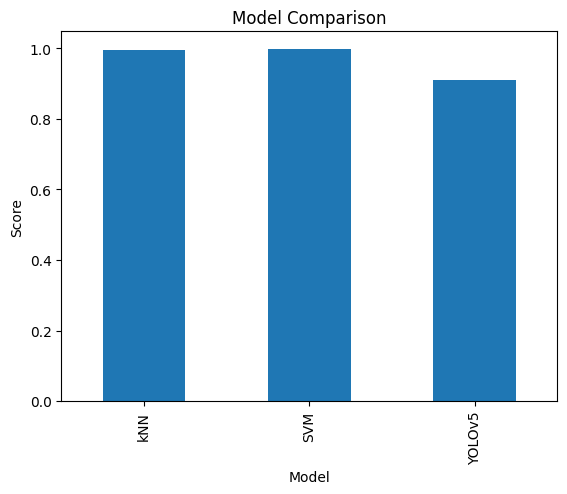

In [26]:
# %% [Cell 11] Compare classical ML vs deep learning
comparison = pd.DataFrame({
    "Model": ["kNN", "SVM", "YOLOv5"],
    "Metric": ["Accuracy", "Accuracy", "mAP50"],
    "Score": [
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, svm_pred),
        metrics.box.map50
    ]
})
print(comparison)
comparison.plot(x="Model", y="Score", kind="bar", legend=False, title="Model Comparison")
plt.ylabel("Score")
plt.show()


## Cell 10 (Extended): Evaluate YOLOv5 Overall and Per Class

Tests the trained model on the validation images and reports detection quality.

**Overall scores:**
- **mAP50** – overall detection accuracy, counting a detection as correct if its box overlaps the real cell by at least 50%. Closer to 1.0 is better
- **mAP50-95** – a stricter score that also checks how precisely the boxes are placed
- **Precision** – of all boxes the model drew, how many were correct
- **Recall** – of all real cells, how many the model found

**Per-class scores:**
The loop prints AP50 and AP50-95 for each cell type (Platelets, RBC, WBC), so you can see which class the model detects best and which it struggles with.

In [28]:
metrics = model.val()

print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)
print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)

# Per-class results
for i, cls_name in enumerate(classes):
    print(f"{cls_name}: AP50={metrics.box.ap50[i]:.3f}, AP50-95={metrics.box.ap[i]:.3f}")

Ultralytics 8.4.153 🚀 Python-3.12.13 torch-2.10.0+cu128 CUDA:0 (Tesla T4, 14912MiB)
YOLOv5s summary (fused): 84 layers, 9,112,697 parameters, 0 gradients, 23.8 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1273.5±274.4 MB/s, size: 37.0 KB)
val: Scanning /kaggle/working/yolo_data/labels/val.cache... 87 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 87/87 26.1Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 6/6 2.6it/s 2.3s0.3s
                   all         87       1138      0.861      0.865       0.91      0.633
             Platelets         45         83      0.779      0.831      0.868      0.466
                   RBC         83        968      0.821      0.762      0.876      0.626
                   WBC         86         87      0.983          1      0.987      0.808
Speed: 1.3ms preprocess, 7.2ms inference, 0.0ms loss, 12.5ms postprocess per image
Results saved to /kaggle/working/runs/detect/

## Cell 11: Display the YOLO Confusion Matrix

Finds and shows the confusion matrix image that YOLO saved automatically during training/validation.

- **`run_dir`** – the folder where YOLO saved its results
- **`glob.glob(...)`** – searches for `confusion_matrix.png` inside that folder (and any similar folders like `bccd_yolov52`, which YOLO creates when `model.val()` is run again)
- **`print(cm_path)`** – shows the file path(s) found, so you can confirm the file exists
- **`display(Image(...))`** – shows the last (most recent) confusion matrix image in the notebook

The matrix shows, for each real cell type, what YOLO predicted. Correct predictions are along the diagonal; anything off the diagonal is a mistake (including missed cells, shown under "background").

['/kaggle/working/runs/bccd_yolov5/confusion_matrix.png']


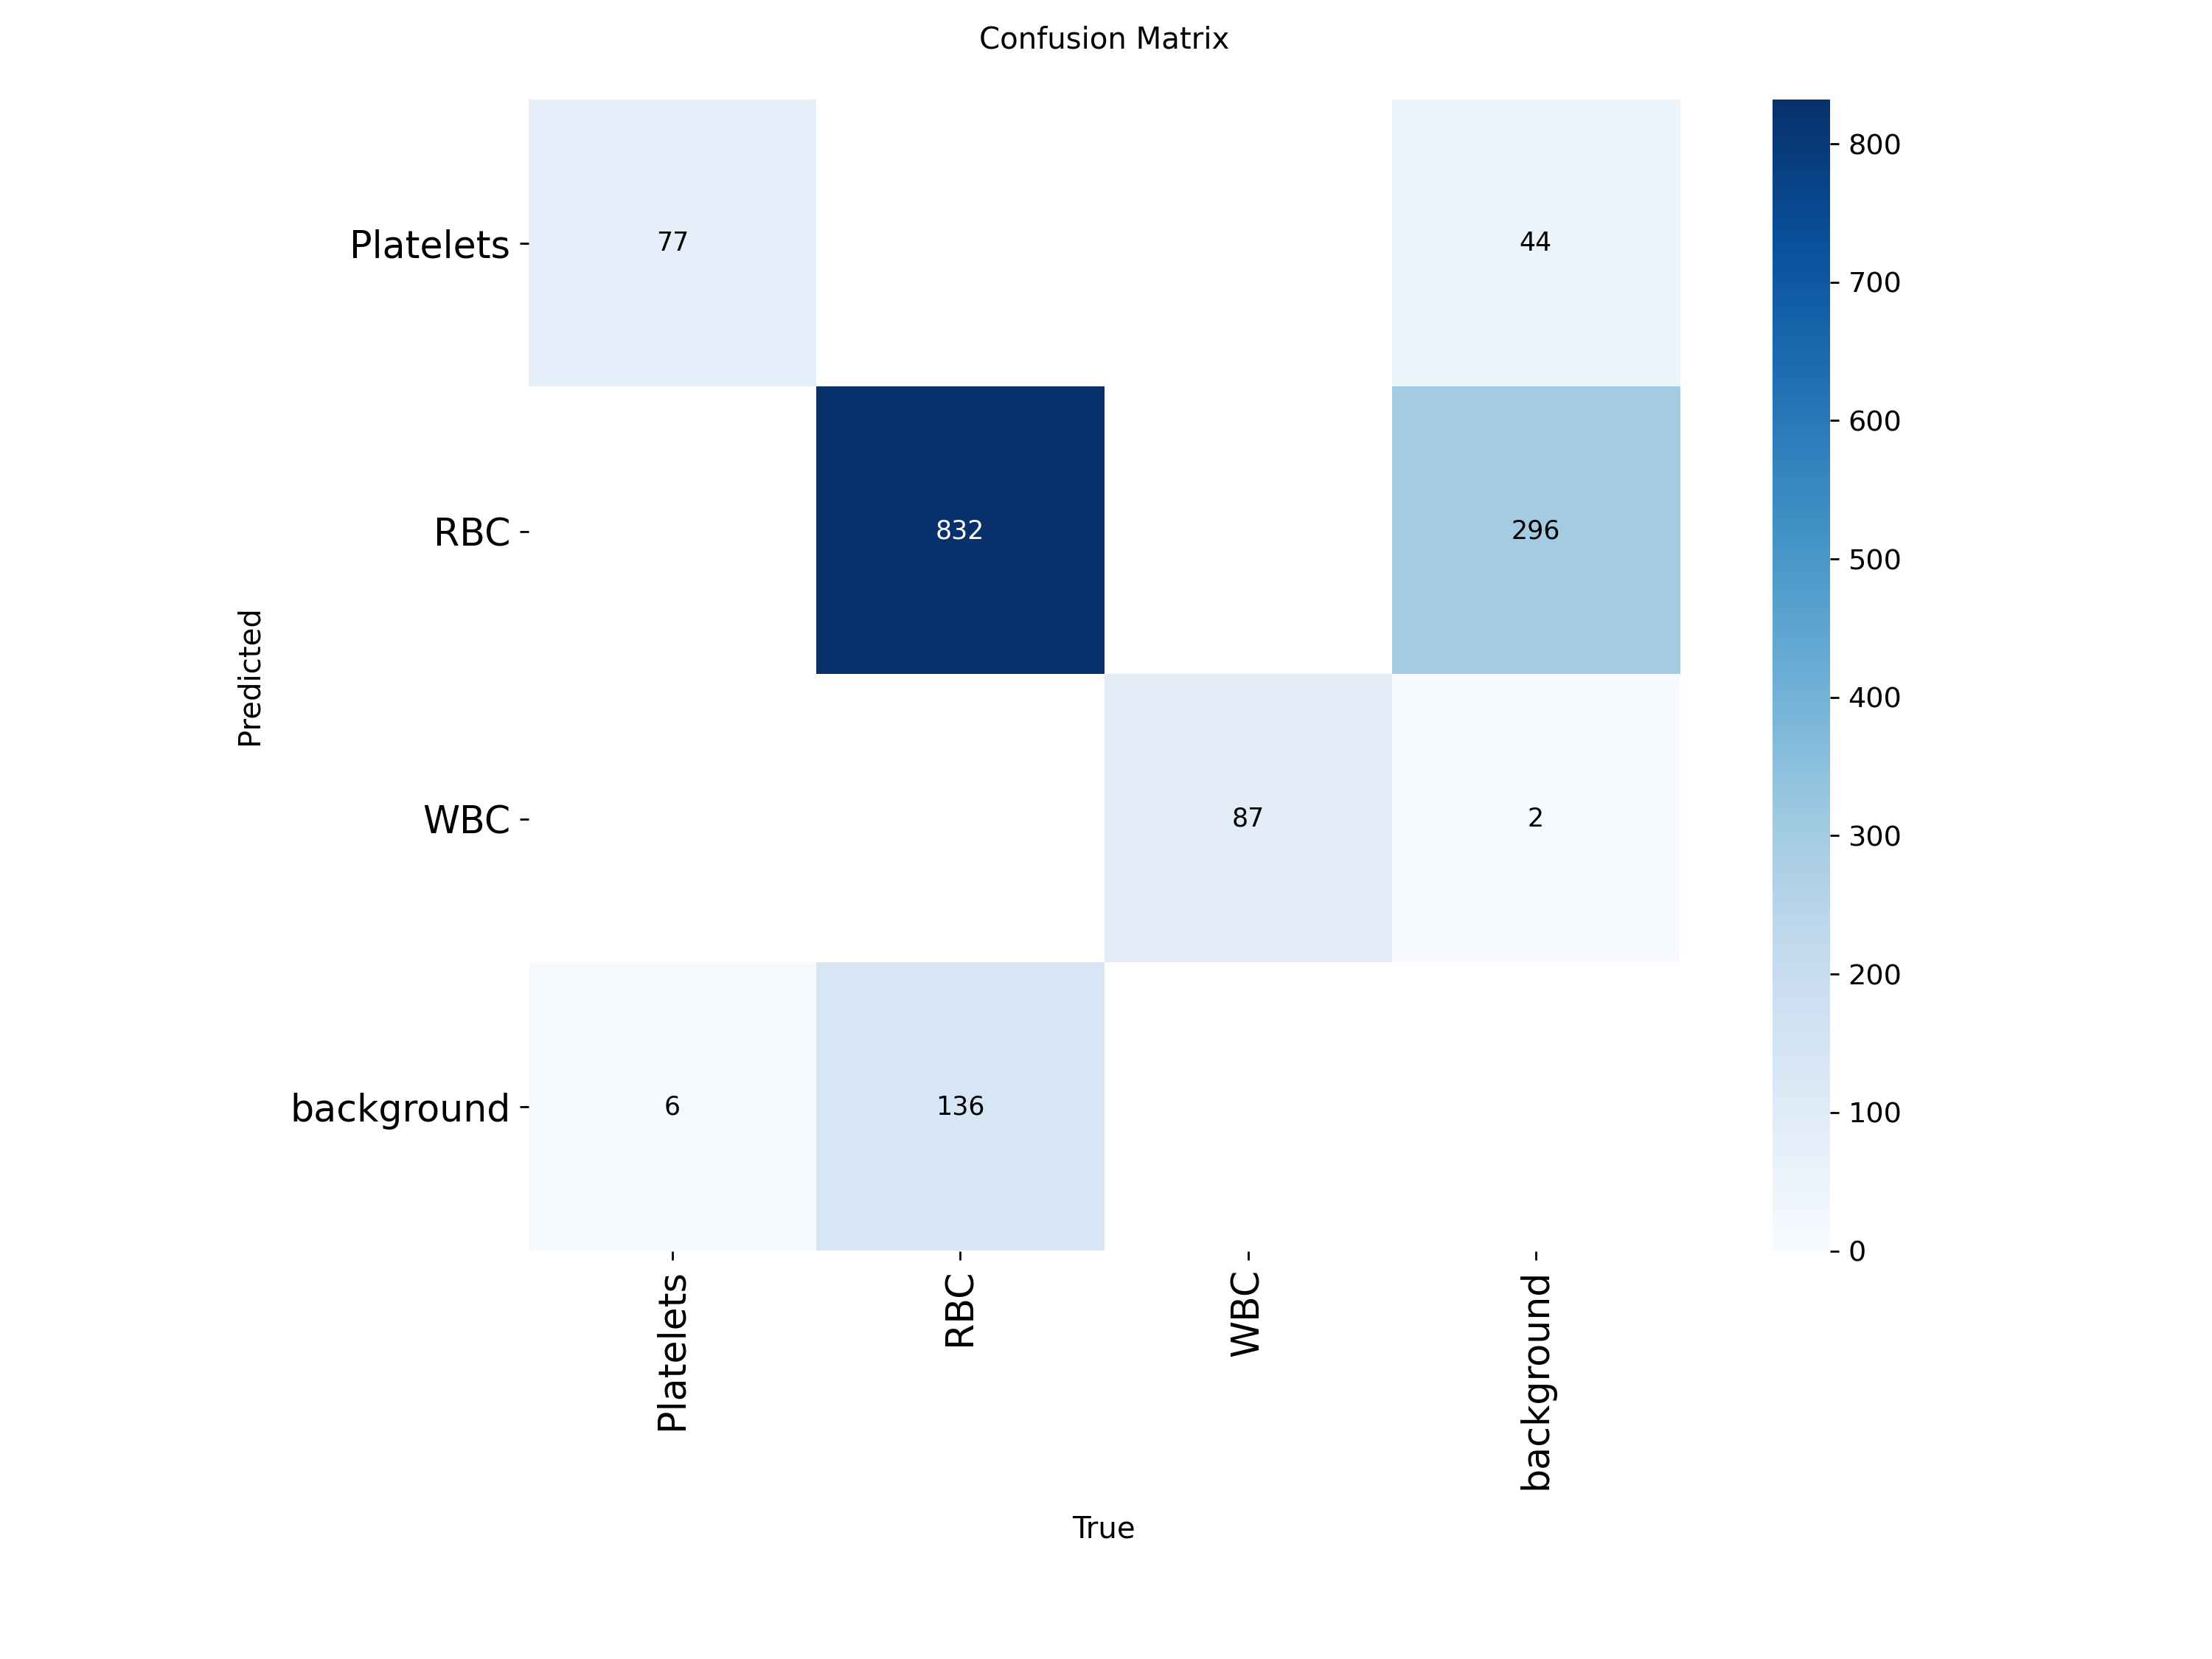

In [29]:
import glob
from IPython.display import Image, display

run_dir = "/kaggle/working/runs/bccd_yolov5"  # adjust if val created a new folder like bccd_yolov52
cm_path = glob.glob(f"{run_dir}*/confusion_matrix.png")
print(cm_path)
display(Image(filename=cm_path[-1]))